In [ ]:
'''
Team 1: Amanda Rodriguez

Project Title: Stock Market Prediction and Analytics

Dataset: yahoo finance stock dataset

Notebook for ARIMA Model
'''

Loading/Formatting Data

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pandas_datareader.data import DataReader
import yfinance as yf
from pandas_datareader import data as pdr
#loading libraries to read stock data
#yf.pdr_override()

from datetime import datetime

alist = ['AAPL', 'GOOG', 'MSFT', 'AMZN']

#start and end dates (start of 2022 to end of 2024)
start_date = datetime(2022, 1, 1)
end_date = datetime(2024, 12, 31)

#format stocks better
for stock in alist:
    globals()[stock] = yf.download(stock, start_date, end_date, auto_adjust= False)


company_list = [AAPL, GOOG, MSFT, AMZN]
company_name = ["APPLE", "GOOGLE", "MICROSOFT", "AMAZON"]

for company, comp_name in zip(company_list, company_name):
    company["company_name"] = comp_name

df = pd.concat(company_list, axis=0)
df.tail(10)


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Price      Adj Close Close High  Low Open Volume company_name Adj Close Close  \
Ticker          AAPL  AAPL AAPL AAPL AAPL   AAPL                   GOOG  GOOG   
Date                                                                            
2024-12-16       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-17       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-18       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-19       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-20       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-23       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-24       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-26       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-27       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   
2024-12-30       NaN   NaN  NaN  NaN  NaN    NaN       AMAZON       NaN   NaN   

Price      High  ...       Low Open Volume   Adj Close       Close  \
Ticker     GOOG  ... MSFT MSFT MSFT   MSFT        AMZN        AMZN   
Date             ...                                                 
2024-12-16  NaN  ...  NaN  NaN  NaN    NaN  232.929993  232.929993   
2024-12-17  NaN  ...  NaN  NaN  NaN    NaN  231.149994  231.149994   
2024-12-18  NaN  ...  NaN  NaN  NaN    NaN  220.520004  220.520004   
2024-12-19  NaN  ...  NaN  NaN  NaN    NaN  223.289993  223.289993   
2024-12-20  NaN  ...  NaN  NaN  NaN    NaN  224.919998  224.919998   
2024-12-23  NaN  ...  NaN  NaN  NaN    NaN  225.059998  225.059998   
2024-12-24  NaN  ...  NaN  NaN  NaN    NaN  229.050003  229.050003   
2024-12-26  NaN  ...  NaN  NaN  NaN    NaN  227.050003  227.050003   
2024-12-27  NaN  ...  NaN  NaN  NaN    NaN  223.750000  223.750000   
2024-12-30  NaN  ...  NaN  NaN  NaN    NaN  221.300003  221.300003   

Price             High         Low        Open      Volume  
Ticker            AMZN        AMZN        AMZN        AMZN  
Date                                                        
2024-12-16  233.000000  228.009995  230.229996  37552100.0  
2024-12-17  232.729996  227.850006  232.389999  35948100.0  
2024-12-18  231.399994  220.110001  230.770004  43281400.0  
2024-12-19  226.089996  222.919998  224.910004  39918700.0  
2024-12-20  226.210007  218.729996  219.839996  88279200.0  
2024-12-23  226.880005  223.899994  225.009995  28070000.0  
2024-12-24  229.139999  226.130005  226.940002  15007500.0  
2024-12-26  228.500000  226.669998  228.500000  16146700.0  
2024-12-27  226.029999  220.899994  225.600006  27367100.0  
2024-12-30  223.000000  218.429993  220.059998  28321200.0  

[10 rows x 25 columns]

ARIMA Models (for Apple, Google, Microsoft, and Amazon)

[*********************100%***********************]  1 of 1 completed

YF.download() has changed argument auto_adjust default to True
Mean Absolute Error (MAE): 2.5840181651911216
Mean Squared Error (MSE): 10.214556594147782
Root Mean Squared Error (RMSE): 3.1960219952540663


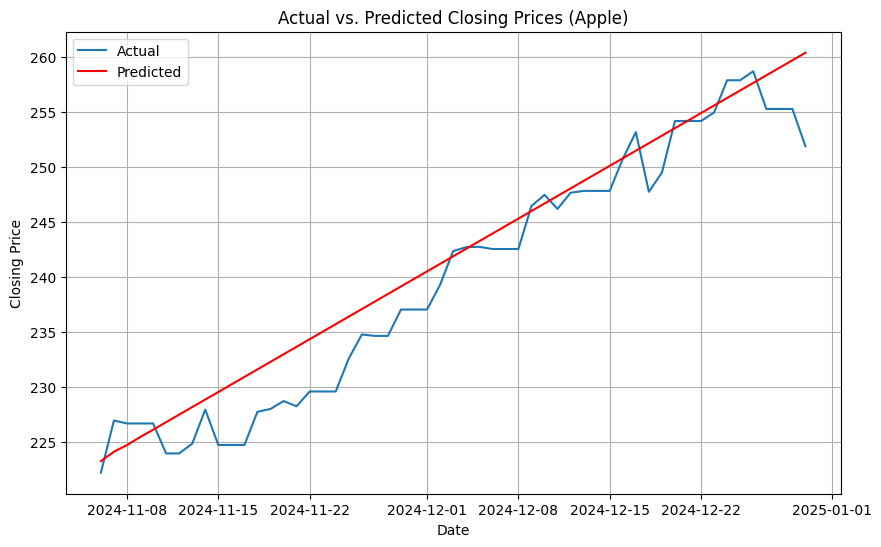

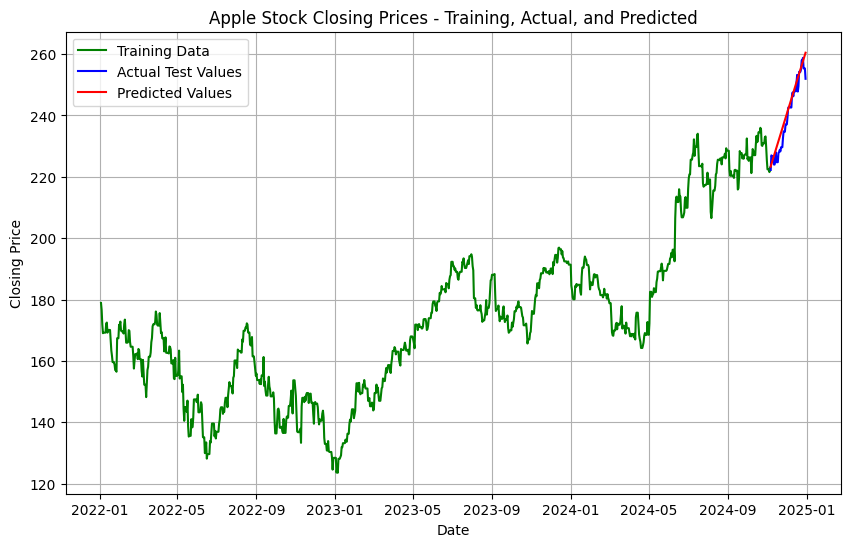

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Download Apple data
data_app = yf.download('AAPL', start='2022-01-01', end='2024-12-31')
data_app = data_app[['Close']]

# Preprocessing
freq = pd.infer_freq(data_app.index) # Infer frequency
data_app = data_app.asfreq(freq)
data_app = data_app.ffill() # Forward fill to handle null values

# Split data into 95% training, 5% testing
train_size = int(len(data_app) * 0.95)
train_app, test_app = data_app[:train_size], data_app[train_size:]

# Create and fit model
model_app = ARIMA(train_app, order=(1, 2, 0)) # Optimal params = (1, 2, 0)
model_app_fit = model_app.fit()
forecast_app = model_app_fit.predict(start=len(train_app), end=len(train_app) + len(test_app) - 1)

# Error metrics
mae_app = mean_absolute_error(test_app, forecast_app)
mse_app = mean_squared_error(test_app, forecast_app)
rmse_app = np.sqrt(mse_app)

print(f'Mean Absolute Error (MAE): {mae_app}')
print(f'Mean Squared Error (MSE): {mse_app}')
print(f'Root Mean Squared Error (RMSE): {rmse_app}')

# Actual vs predicted closing prices
plt.figure(figsize=(10, 6))
plt.plot(test_app.index, test_app.values, label='Actual')
plt.plot(test_app.index, forecast_app, label='Predicted', color='red')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Actual vs. Predicted Closing Prices (Apple)')
plt.legend()
plt.grid(True)
plt.show()

# Plot training data, actual test values, and predicted values
plt.figure(figsize=(10, 6))
plt.plot(train_app.index, train_app.values, label='Training Data', color='green')  # Training data in blue
plt.plot(test_app.index, test_app.values, label='Actual Test Values', color='blue')  # Actual test values in green
plt.plot(test_app.index, forecast_app, label='Predicted Values', color='red')  # Predicted values in red
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Apple Stock Closing Prices - Training, Actual, and Predicted')
plt.legend()
plt.grid(True)
plt.show()

[*********************100%***********************]  1 of 1 completed


Mean Absolute Error (MAE): 15.894520275571603
Mean Squared Error (MSE): 395.5611998634645
Root Mean Squared Error (RMSE): 19.888720417952094


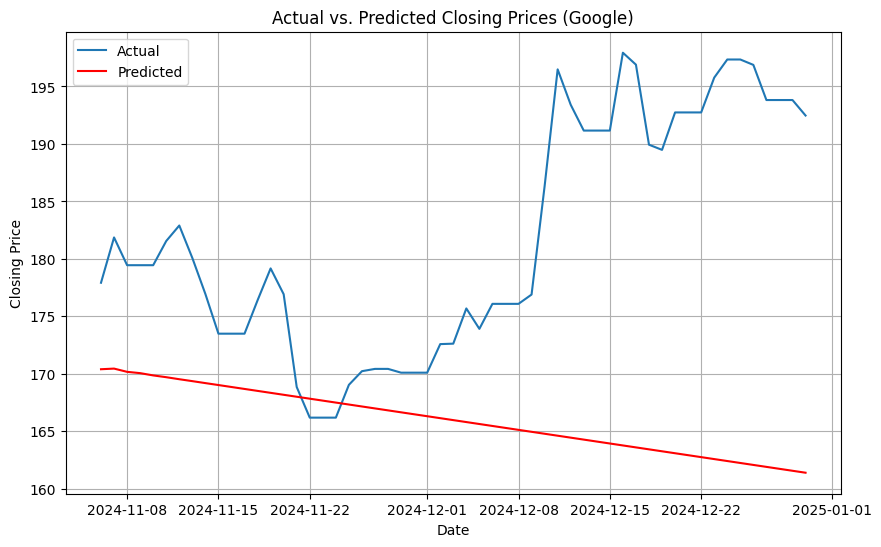

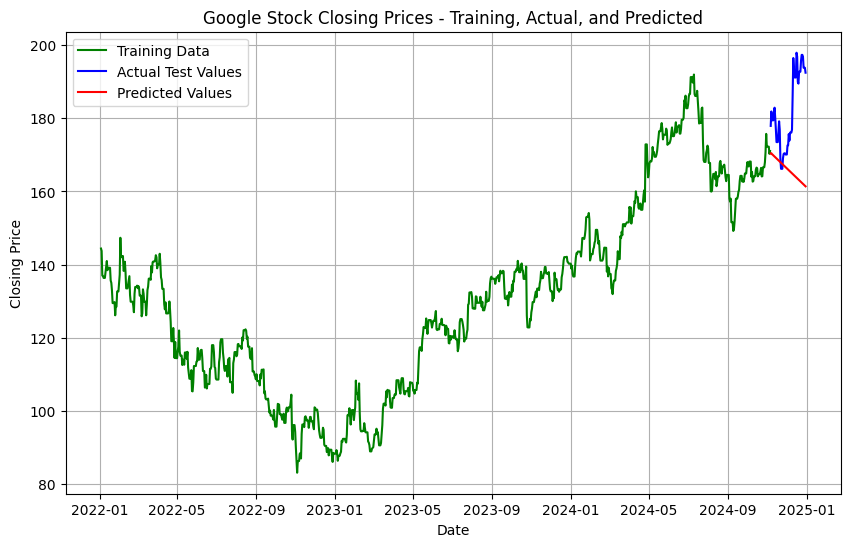

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Download Google data
data_ggl = yf.download('GOOG', start='2022-01-01', end='2024-12-31')
data_ggl = data_ggl[['Close']]

# Preprocessing
freq = pd.infer_freq(data_ggl.index) # Infer frequency
data_ggl = data_ggl.asfreq(freq)
data_ggl = data_ggl.ffill() # Forward fill to handle null values

# Split data into 95% training, 5% testing
train_size = int(len(data_ggl) * 0.95)
train_ggl, test_ggl = data_ggl[:train_size], data_ggl[train_size:]

# Create and fit model
model_ggl = ARIMA(train_ggl, order=(1, 2, 0)) # Optimal params = (1, 4, 2)
model_ggl_fit = model_ggl.fit()
forecast_ggl = model_ggl_fit.predict(start=len(train_ggl), end=len(train_ggl) + len(test_ggl) - 1)

# Error metrics
mae_ggl = mean_absolute_error(test_ggl, forecast_ggl)
mse_ggl = mean_squared_error(test_ggl, forecast_ggl)
rmse_ggl = np.sqrt(mse_ggl)

print(f'Mean Absolute Error (MAE): {mae_ggl}')
print(f'Mean Squared Error (MSE): {mse_ggl}')
print(f'Root Mean Squared Error (RMSE): {rmse_ggl}')

# Actual vs predicted closing prices
plt.figure(figsize=(10, 6))
plt.plot(test_ggl.index, test_ggl.values, label='Actual')
plt.plot(test_ggl.index, forecast_ggl, label='Predicted', color='red')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Actual vs. Predicted Closing Prices (Google)')
plt.legend()
plt.grid(True)
plt.show()

# Plot training data, actual test values, and predicted values
plt.figure(figsize=(10, 6))
plt.plot(train_ggl.index, train_ggl.values, label='Training Data', color='green')  # Training data in blue
plt.plot(test_ggl.index, test_ggl.values, label='Actual Test Values', color='blue')  # Actual test values in green
plt.plot(test_ggl.index, forecast_ggl, label='Predicted Values', color='red')  # Predicted values in red
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Google Stock Closing Prices - Training, Actual, and Predicted')
plt.legend()
plt.grid(True)
plt.show()

[*********************100%***********************]  1 of 1 completed


Mean Absolute Error (MAE): 20.03159001552969
Mean Squared Error (MSE): 603.6167238268858
Root Mean Squared Error (RMSE): 24.56861257431697


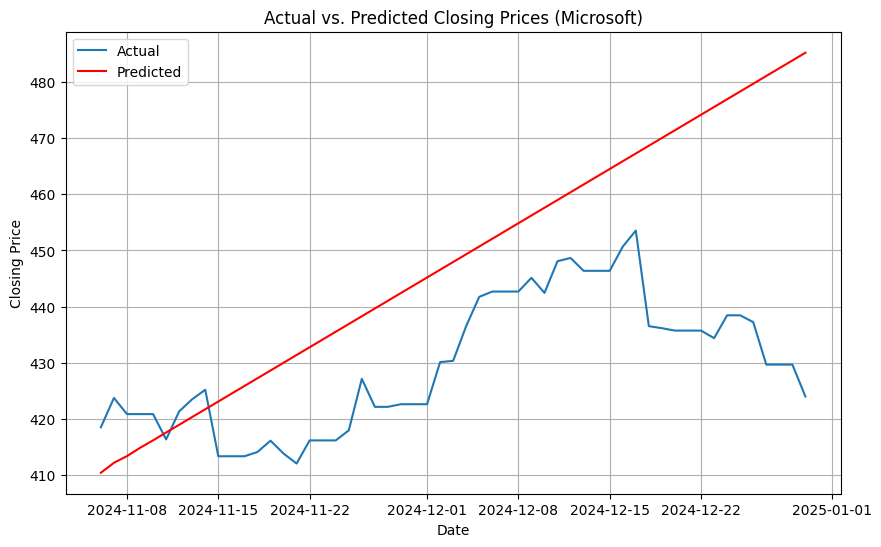

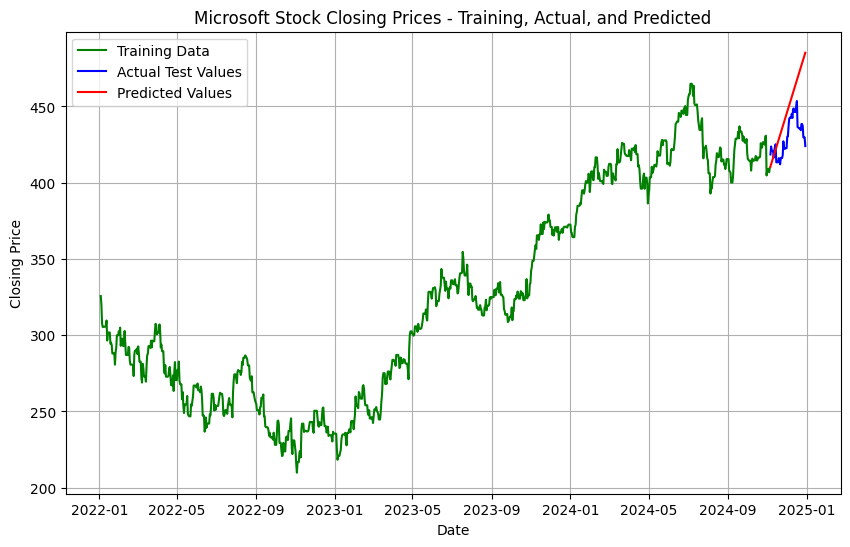

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Download Microsoft data
data_mst = yf.download('MSFT', start='2022-01-01', end='2024-12-31')
data_mst = data_mst[['Close']]

# Preprocessing
freq = pd.infer_freq(data_mst.index) # Infer frequency
data_mst = data_mst.asfreq(freq)
data_mst = data_mst.ffill() # Forward fill to handle null values

# Split data into 95% training, 5% testing
train_size = int(len(data_mst) * 0.95)
train_mst, test_mst = data_mst[:train_size], data_mst[train_size:]

# Create and fit model
model_mst = ARIMA(train_mst, order=(1, 2, 0)) # Optimal params = (4, 2, 3)
model_mst_fit = model_mst.fit()
forecast_mst = model_mst_fit.predict(start=len(train_mst), end=len(train_mst) + len(test_mst) - 1)

# Error metrics
mae_mst = mean_absolute_error(test_mst, forecast_mst)
mse_mst = mean_squared_error(test_mst, forecast_mst)
rmse_mst = np.sqrt(mse_mst)

print(f'Mean Absolute Error (MAE): {mae_mst}')
print(f'Mean Squared Error (MSE): {mse_mst}')
print(f'Root Mean Squared Error (RMSE): {rmse_mst}')

# Actual vs predicted closing prices
plt.figure(figsize=(10, 6))
plt.plot(test_mst.index, test_mst.values, label='Actual')
plt.plot(test_mst.index, forecast_mst, label='Predicted', color='red')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Actual vs. Predicted Closing Prices (Microsoft)')
plt.legend()
plt.grid(True)
plt.show()

# Plot training data, actual test values, and predicted values
plt.figure(figsize=(10, 6))
plt.plot(train_mst.index, train_mst.values, label='Training Data', color='green')  # Training data in blue
plt.plot(test_mst.index, test_mst.values, label='Actual Test Values', color='blue')  # Actual test values in green
plt.plot(test_mst.index, forecast_mst, label='Predicted Values', color='red')  # Predicted values in red
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Microsoft Stock Closing Prices - Training, Actual, and Predicted')
plt.legend()
plt.grid(True)
plt.show()

[*********************100%***********************]  1 of 1 completed


Mean Absolute Error (MAE): 33.29744310851623
Mean Squared Error (MSE): 1472.7071317245259
Root Mean Squared Error (RMSE): 38.37586652734406


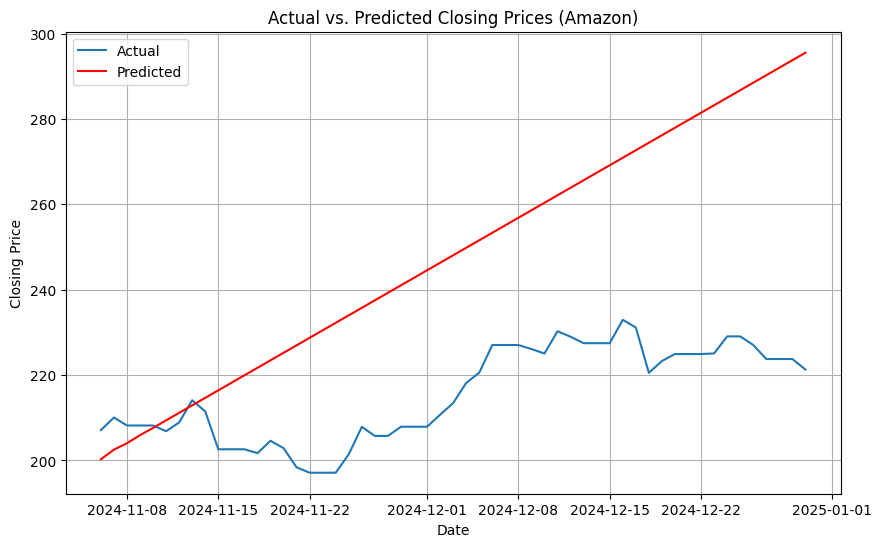

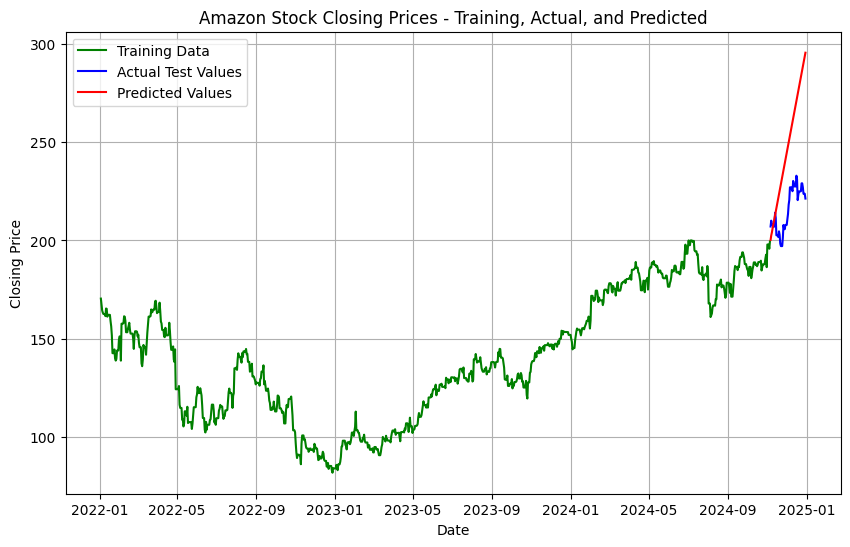

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Download Amazon data
data_amz = yf.download('AMZN', start='2022-01-01', end='2024-12-31')
data_amz = data_amz[['Close']]

# Preprocessing
freq = pd.infer_freq(data_amz.index) # Infer frequency
data_amz = data_amz.asfreq(freq)
data_amz = data_amz.ffill() # Forward fill to handle null values

# Split data into 95% training, 5% testing
train_size = int(len(data_amz) * 0.95)
train_amz, test_amz = data_amz[:train_size], data_amz[train_size:]

# Create and fit model
model_amz = ARIMA(train_amz, order=(1, 2, 0)) # Optimal params = (1, 4, 4)
model_amz_fit = model_amz.fit()
forecast_amz = model_amz_fit.predict(start=len(train_amz), end=len(train_amz) + len(test_amz) - 1)

# Error metrics
mae_amz = mean_absolute_error(test_amz, forecast_amz)
mse_amz = mean_squared_error(test_amz, forecast_amz)
rmse_amz = np.sqrt(mse_amz)

print(f'Mean Absolute Error (MAE): {mae_amz}')
print(f'Mean Squared Error (MSE): {mse_amz}')
print(f'Root Mean Squared Error (RMSE): {rmse_amz}')

# Actual vs predicted closing prices
plt.figure(figsize=(10, 6))
plt.plot(test_amz.index, test_amz.values, label='Actual')
plt.plot(test_amz.index, forecast_amz, label='Predicted', color='red')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Actual vs. Predicted Closing Prices (Amazon)')
plt.legend()
plt.grid(True)
plt.show()

# Plot training data, actual test values, and predicted values
plt.figure(figsize=(10, 6))
plt.plot(train_amz.index, train_amz.values, label='Training Data', color='green')  # Training data in blue
plt.plot(test_amz.index, test_amz.values, label='Actual Test Values', color='blue')  # Actual test values in green
plt.plot(test_amz.index, forecast_amz, label='Predicted Values', color='red')  # Predicted values in red
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.title('Amazon Stock Closing Prices - Training, Actual, and Predicted')
plt.legend()
plt.grid(True)
plt.show()

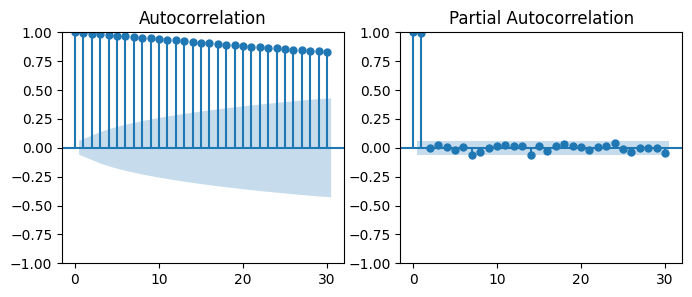

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ACF/PACF Plots for initial parameter guess
# ACF determines q, PACF determines p
# Gradual decline suggests value of 0, sharp cutoff suggests value on x-axis at cutoff
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
plot_acf(train_app, ax=axes[0], lags=30)
plot_pacf(train_app, ax=axes[1], lags=30)
plt.show()

# (Autoregressive order) p = # of past values used to predict current value
# (Differencing order) d = # of times data must be differenced to make it stationary
# (Moving average order) q = # of past values' errors to consider for current prediction

In [ ]:
# Determing best parameters (p, d, q) using manual gridsearch

# (Autoregressive order) p = # of past values used to predict current value
# (Differencing order) d = # of times data must be differenced to make it stationary
# (Moving average order) q = # of past values' errors to consider for current prediction

# Ranges for each parameter
p_values = range(0,5)
d_values = range(0,5)
q_values = range(0,5)

# Store results
best_params = (0,0,0)
best_mse = float('inf')

# Loop through each parameter combination
for p in p_values:
  for d in d_values:
    for q in q_values:
      order = (p, d, q)
      try:
        model = ARIMA(train_app, order=order)
        model_fit = model.fit()
        forecast_app = model_fit.predict(start=len(train_app), end=len(train_app) + len(test_app) - 1)
        mse = mean_squared_error(test_app, forecast_app)
        if mse < best_mse:
          best_mse = mse
          best_params = order
      except Exception as e:
        print(f'Error for order {order}: {e}')
        continue

print(f'Best parameters: {best_params}')

In [ ]:
# NOT USED IN MODELS - Code for manual gridsearch with cross-validaton
# Takes 25 minutes to run

from sklearn.model_selection import TimeSeriesSplit

# Ranges for each parameter
p_values = range(0, 6)
d_values = range(0, 6)
q_values = range(0, 6)

# Store results
best_params = (0, 0, 0)
best_mse = float('inf')

# Number of folds for cross-validation
n_splits = 5

# Create TimeSeriesSplit object
tscv = TimeSeriesSplit(n_splits=n_splits)

# Loop through each parameter combination
for p in p_values:
    for d in d_values:
        for q in q_values:
            order = (p, d, q)
            try:
                # Perform cross-validation
                mse_scores = []
                for train_index, test_index in tscv.split(train_app):
                    train_fold = train_app.iloc[train_index]
                    test_fold = train_app.iloc[test_index]

                    model = ARIMA(train_fold, order=order)
                    model_fit = model.fit()
                    forecast = model_fit.predict(start=len(train_fold), end=len(train_fold) + len(test_fold) - 1)
                    mse_scores.append(mean_squared_error(test_fold, forecast))

                # Average MSE across folds
                avg_mse = np.mean(mse_scores)

                # Update best parameters if average MSE is lower
                if avg_mse < best_mse:
                    best_mse = avg_mse
                    best_params = order

            except Exception as e:
                print(f'Error for order {order}: {e}')
                continue

print(f'Best parameters: {best_params}')